# Training the models

**calling the models**

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

#importing preprocessing funcs from src

import sys
sys.path.append('..')

from src.preprocessing import load_and_split_data, build_preprocessor

X_train, X_test, y_train, y_test = load_and_split_data('../data/student_mental_health.csv')
preprocessor = build_preprocessor(X_train)

**setup the models**

In [3]:
model1 = LogisticRegression(max_iter=1000, random_state=42)

model2 = RandomForestClassifier(random_state=42)

model3 = GradientBoostingClassifier(random_state=42)

models = {'logistic regression': model1, 'random forest': model2, 'gradient boosting': model3}

**train and evaluate**

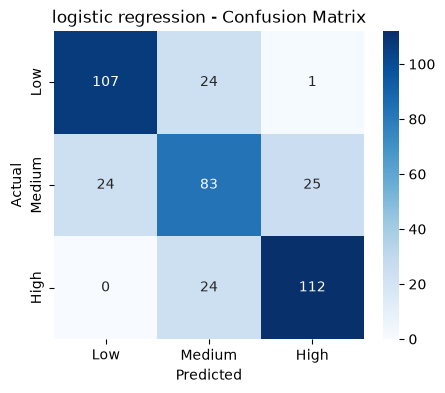

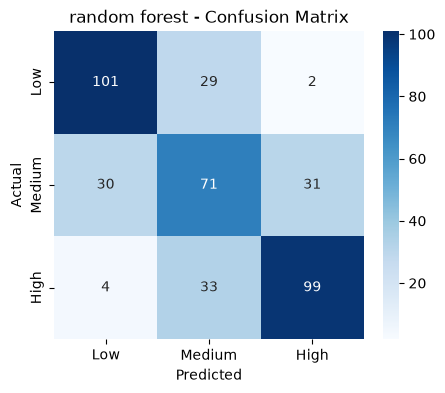

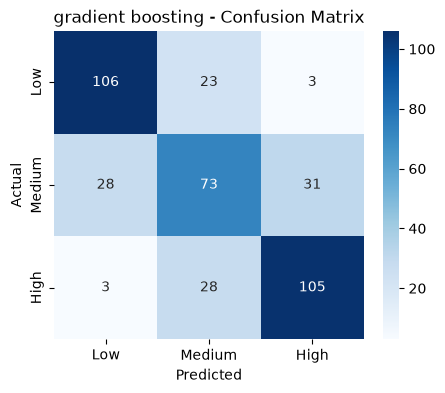

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,logistic regression,0.7550,0.754568,0.7550,0.754762,0.913723
1,random forest,0.6775,0.678054,0.6775,0.677687,0.857947
2,gradient boosting,0.7100,0.706437,0.7100,0.707914,0.882753


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

results = []

for name, model in models.items():
    pipe = Pipeline([('preprocessor', build_preprocessor(X_train)), ('model', model)]).fit(X_train, y_train)
    
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)
    
    results.append({
    'Model': name,
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, average='weighted'),
    'Recall': recall_score(y_test, y_pred, average='weighted'),
    'F1-Score': f1_score(y_test, y_pred, average='weighted'),
    'ROC-AUC': roc_auc_score(y_test, y_prob, multi_class='ovr')
    })
    
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Low', 'Medium', 'High'],
                yticklabels=['Low', 'Medium', 'High'])
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
    
    

results_df = pd.DataFrame(results)
display(results_df)

### Model Comparison & Selection for Step 4

#### 1. Baseline Performance Summary
* **Logistic Regression:** Accuracy: 75.50% | Precision: 75.46% | Recall: 75.50% | F1-Score: 75.48% | ROC-AUC: 0.9137
* **Gradient Boosting:** Accuracy: 71.00% | Precision: 70.64% | Recall: 71.00% | F1-Score: 70.79% | ROC-AUC: 0.8828
* **Random Forest:** Accuracy: 67.75% | Precision: 67.81% | Recall: 67.75% | F1-Score: 67.77% | ROC-AUC: 0.8579

#### 2. Strategy for Step 4 (Hyperparameter Optimization)
Although Logistic Regression leads with baseline settings (75.5% accuracy, 0.914 ROC-AUC), default ensemble trees (Random Forest and Gradient Boosting) often suffer from suboptimal depth and tree counts. 

i decide to **tune all 3 models** in **Étape 4** using `GridSearchCV`:
1. **Logistic Regression:** Tune regularization parameter `C` and solver/penalty.
2. **Random Forest:** Tune `n_estimators`, `max_depth`, and `min_samples_split` to prevent overfitting.
3. **Gradient Boosting:** Tune `learning_rate`, `n_estimators`, and `max_depth` to unlock higher ensemble accuracy.

This gives all model families a fair, fully optimized comparison before selecting our final production model.

# tuning with gridSearchCV

In [5]:
from sklearn.model_selection import GridSearchCV


# Logistic Regression Grid
param_grid_lr = {
    'model__C': [0.01, 0.1, 1, 10],
    'model__solver': ['lbfgs', 'saga']
}

# Random Forest Grid
param_grid_rf = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [5, 10, None],
    'model__min_samples_split': [2, 5]
}

# Gradient Boosting Grid
param_grid_gb = {
    'model__n_estimators': [100, 200],
    'model__learning_rate': [0.05, 0.1, 0.2],
    'model__max_depth': [3, 5]
}

grids = {
    'logistic regression': param_grid_lr,
    'random forest': param_grid_rf,
    'gradient boosting': param_grid_gb,
}

tuned_results = []
best_pipes = {}

for name , model in models.items():
    
    print(f"Tuning {name}...")
    pipe = Pipeline([
        ('preprocessor', build_preprocessor(X_train)),
        ('model', model)
    ])

    grid = GridSearchCV(
        estimator=pipe,
        param_grid=grids[name],
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )
    
    grid.fit(X_train, y_train)
    best_pipes[name] = grid.best_estimator_
    
    y_pred = grid.predict(X_test)
    y_prob = grid.predict_proba(X_test)
    
    
    tuned_results.append({
    'Model': name,
    'Best CV Score': grid.best_score_,
    'Test Accuracy': accuracy_score(y_test, y_pred),
    'Test Precision': precision_score(y_test, y_pred, average='weighted'),
    'Test Recall': recall_score(y_test, y_pred, average='weighted'),
    'Test F1-Score': f1_score(y_test, y_pred, average='weighted'),
    'Test ROC-AUC': roc_auc_score(y_test, y_prob, multi_class='ovr'),
    'Best Params': grid.best_params_
    })
    
    

tuned_df = pd.DataFrame(tuned_results)
display(tuned_df)

Tuning logistic regression...
Tuning random forest...
Tuning gradient boosting...


,Model,Best CV Score,Test Accuracy,Test Precision,Test Recall,Test F1-Score,Test ROC-AUC,Best Params
0,logistic regression,0.754375,0.755,0.754568,0.755,0.754762,0.913723,"{'model__C': 1, 'model__solver': 'lbfgs'}"
1,random forest,0.695000,0.705,0.699529,0.705,0.701582,0.866686,"{'model__max_depth': 10, 'model__min_samples_s..."
2,gradient boosting,0.696875,0.710,0.706437,0.710,0.707914,0.882753,"{'model__learning_rate': 0.1, 'model__max_dept..."


# classification report

print("Classification Report (Logistic Regression):")
              precision    recall  f1-score   support

         low       0.82      0.81      0.81       132
      medium       0.63      0.63      0.63       132
        high       0.81      0.82      0.82       136

    accuracy                           0.76       400
   macro avg       0.75      0.75      0.75       400
weighted avg       0.75      0.76      0.75       400



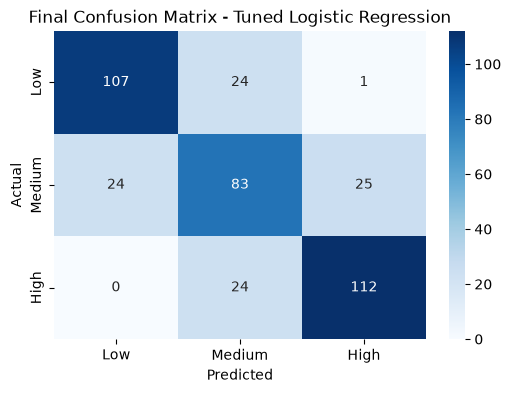

In [7]:
from sklearn.metrics import classification_report



best_model = best_pipes['logistic regression']

y_pred = best_model.predict(X_test)


print('print("Classification Report (Logistic Regression):")')
print(classification_report(y_test,y_pred, target_names=['low', 'medium', 'high']))

cm = confusion_matrix(y_test, y_pred)


plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low', 'Medium', 'High'],
            yticklabels=['Low', 'Medium', 'High'])
plt.title('Final Confusion Matrix - Tuned Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# save the model

In [8]:
import joblib

joblib.dump(best_model, '../models/best_model.joblib')
print("Model saved successfully in models/best_model.joblib")

loaded_model = joblib.load('../models/best_model.joblib')


sample = X_test.iloc[[0]]
pred = loaded_model.predict(sample)
print(f"Test prediction on sample: {pred[0]} (True label: {y_test.iloc[0]})")

Model saved successfully in models/best_model.joblib
Test prediction on sample: 2 (True label: 2)
